# Chapitre 8 - Cours 2 : délais non bornés et détection des pannes

Le cours 1 a montré que le délai d'expiration est le seul moyen général de détecter une
panne. Reste à le choisir. Ce notebook explique **d'où vient la variabilité** des délais
réseau (les files d'attente), comment **régler** un délai (fixe ou adaptatif, jusqu'au
détecteur « phi accrual ») et **pourquoi** nos réseaux ne garantissent aucun délai
maximal alors que le téléphone le faisait. Il couvre les sections *Timeouts and
Unbounded Delays* (*Network congestion and queueing*, encadré *TCP Versus UDP*)
et *Synchronous Versus Asynchronous Networks* (*Can we not simply make network delays predictable?*, encadré *Latency and Resource Utilization*).

**Plan.**

1. Choisir un délai d'expiration : un compromis sans bonne réponse.
2. Congestion et files d'attente : d'où viennent les délais.
3. Des délais adaptatifs : estimateur de TCP et détecteur phi accrual.
4. Réseaux synchrones contre réseaux asynchrones.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Choisir un délai d'expiration (section *Timeouts and Unbounded Delays*)

**Le monde idéal.** Imaginons un réseau qui livre tout paquet en moins de $d$ (ou le
perd), et des serveurs qui traitent toute requête en moins de $r$. Alors toute requête
réussie reçoit sa réponse en moins de $2d + r$, et ne rien recevoir dans ce délai prouve
une panne : $2d + r$ serait le délai d'expiration parfait.

**Le monde réel.** Les réseaux asynchrones ont des délais **non bornés** (ils livrent
aussi vite que possible, sans maximum garanti) et les serveurs ne garantissent pas de
temps de traitement maximal. Pour la détection de pannes, être rapide **la plupart du
temps** ne suffit pas : avec un délai court, un pic passager suffit à déstabiliser le
système. Regardons la distribution synthétique d'un million d'allers-retours dans un
centre de données (`ds.rtt_samples` : corps log-normal de médiane 0,5 ms et rares
surcoûts de queue lourde).

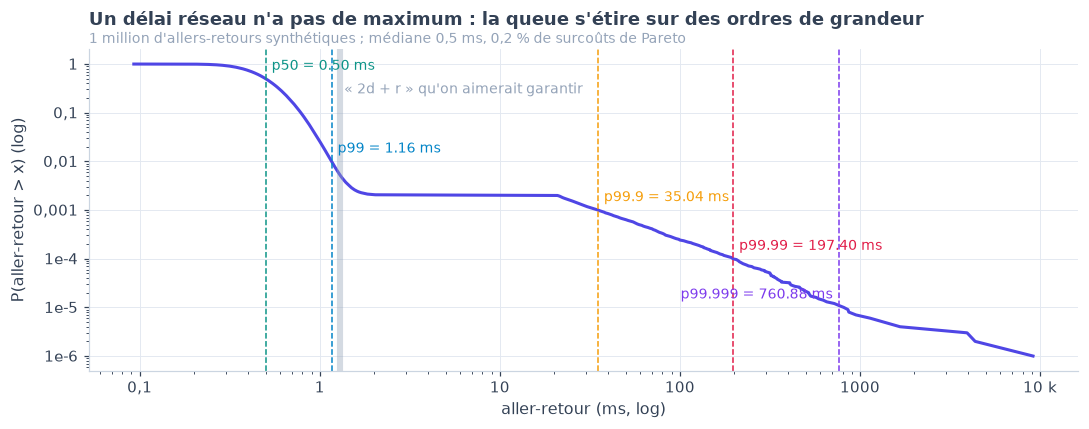

p50          0.50
p99          1.16
p99.9       35.04
p99.99     197.40
p99.999    760.88
Name: aller-retour (ms), dtype: float64

In [2]:
rtt = ds.rtt_samples(1_000_000, seed=1)
qs = [50, 99, 99.9, 99.99, 99.999]
vals = np.percentile(rtt, qs)
x = np.sort(rtt)
idx = np.unique(np.r_[np.arange(0, x.size, 500), x.size - np.geomspace(1, x.size // 2, 400).astype(int)])
ccdf = 1 - idx / x.size
fig, ax = plt.subplots(figsize=(10, 4))
ax.loglog(x[idx], ccdf, color=INDIGO)
for q, v, c in zip(qs, vals, [TEAL, SKY, AMBER, ROSE, VIOLET]):
    ax.axvline(v, color=c, ls="--", lw=1)
    last = q == qs[-1]
    ax.text(v / 1.08 if last else v * 1.08, (1 - q / 100) * 1.3, f"p{q:g} = {v:.2f} ms", color=c, fontsize=9,
            va="bottom", ha="right" if last else "left")
ax.axvline(1.3, color=GRAY, lw=4, alpha=0.4)
ax.text(1.3 * 1.05, 0.25, "« 2d + r » qu'on aimerait garantir", color=GRAY, fontsize=9)
plain_log_axis(ax)
ax.set_xlabel("aller-retour (ms, log)"); ax.set_ylabel("P(aller-retour > x) (log)")
ax.set_title("Un délai réseau n'a pas de maximum : la queue s'étire sur des ordres de grandeur")
subtitle(ax, "1 million d'allers-retours synthétiques ; médiane 0,5 ms, 0,2 % de surcoûts de Pareto")
plt.tight_layout(); plt.show()
pd.Series(vals, index=[f"p{q:g}" for q in qs], name="aller-retour (ms)").round(2)

La médiane vaut une demi-milliseconde, mais un aller-retour sur mille dépasse 35 ms et
un sur dix mille près de 200 ms : quelle que soit la valeur choisie, **certains**
messages arriveront après. Le choix du délai est donc un **compromis** :

- délai **long** : on attend longtemps avant de déclarer un nœud mort (pendant ce temps,
  les utilisateurs patientent ou voient des erreurs) ;
- délai **court** : on détecte vite, mais on déclare morts des nœuds simplement ralentis
  (pic de charge du nœud ou du réseau).

Quantifions-le avec un détecteur par **battements de cœur** : le nœud surveillé émet un
battement toutes les 100 ms ; le détecteur le soupçonne s'il n'a rien reçu depuis $T$.
On mesure le nombre de **fausses suspicions** par jour (pour un nœud vivant) et le
**délai de détection** moyen d'une vraie panne, pour deux réseaux : calme, et partagé
avec un « voisin bruyant ».

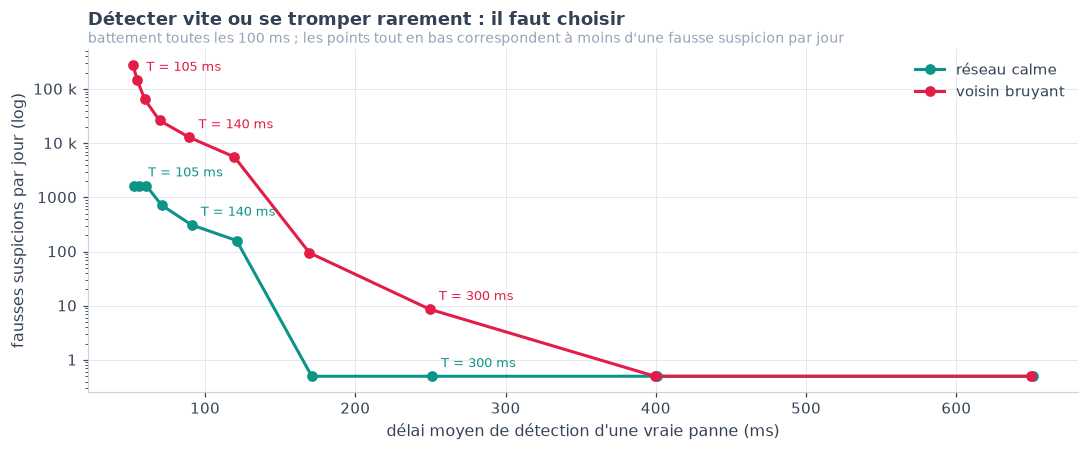

In [3]:
n_hb = 200_000
reseaux = {
    "réseau calme": ds.rtt_samples(n_hb, seed=1, median_ms=1.0, sigma=0.3, spike_prob=0.002, spike_scale_ms=20) / 2,
    "voisin bruyant": ds.rtt_samples(n_hb, seed=2, median_ms=8.0, sigma=0.8, spike_prob=0.02, spike_scale_ms=60) / 2,
}
timeouts = [102, 105, 110, 120, 140, 170, 220, 300, 450, 700]
rows = []
for nom, delays in reseaux.items():
    arr = ds.heartbeat_arrivals(n_hb, 100.0, delays)
    for T in timeouts:
        r = ds.fixed_timeout_eval(arr, T, 100.0)
        rows.append(dict(reseau=nom, T=T, fp_jour=r["faux_positifs"] * 864_000, detection=r["detection_moy"]))
TT = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.2))
for (nom, g), c in zip(TT.groupby("reseau", sort=False), [TEAL, ROSE]):
    ax.plot(g.detection, g.fp_jour.clip(lower=0.5), "o-", color=c, label=nom)
    for _, row in g.iterrows():
        if row["T"] in (105, 140, 300):
            ax.annotate(f"T = {row['T']:g} ms", (row.detection, max(row.fp_jour, 0.5)), textcoords="offset points",
                        xytext=(6, 6), fontsize=8.5, color=c)
ax.set_yscale("log"); plain_log_axis(ax, "y")
ax.set_xlabel("délai moyen de détection d'une vraie panne (ms)")
ax.set_ylabel("fausses suspicions par jour (log)")
ax.set_title("Détecter vite ou se tromper rarement : il faut choisir")
subtitle(ax, "battement toutes les 100 ms ; les points tout en bas correspondent à moins d'une fausse suspicion par jour")
ax.legend()
plt.tight_layout(); plt.show()

Chaque courbe est une **frontière** : on ne peut pas à la fois détecter en 10 ms et ne
jamais se tromper. Surtout, la bonne valeur dépend du réseau : un délai de 140 ms, très
sûr sur le réseau calme, produit des milliers de fausses suspicions par jour avec le
voisin bruyant.

**Déclarer mort trop tôt coûte cher.** Si le nœud était vivant et au milieu d'une action
(envoyer un courriel), un autre nœud la reprend et elle est faite **deux fois**. Et les
responsabilités du nœud « mort » sont transférées aux autres, ce qui ajoute de la charge
au pire moment. Si le nœud n'était que **surchargé**, on obtient une **défaillance en
cascade**. Modélisons dix nœuds de capacités légèrement différentes (100 requêtes/s à
±15 %) qui se partagent une charge occupant 75 % de la capacité totale ; le contrôle de
santé déclare mort un nœud dont le temps de réponse moyen (file M/M/1 :
$R = 1/(\mu - \lambda)$) dépasse $T$. Au départ, **un seul** nœud tombe vraiment.

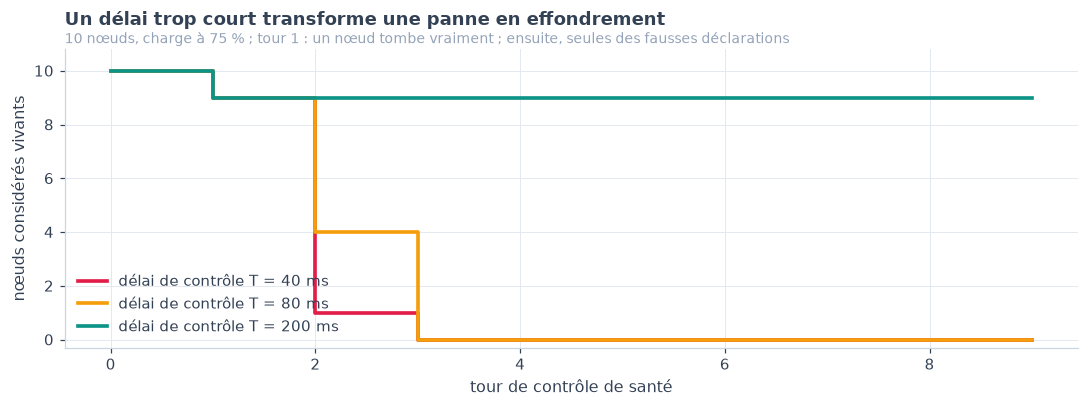

In [4]:
def cascade(T_ms, n=10, charge=0.75, rounds=8, seed=3):
    r = np.random.default_rng(seed)
    mu = 100 * (1 + 0.15 * r.uniform(-1, 1, n))
    lam_tot = charge * mu.sum()
    alive = np.ones(n, bool)
    alive[np.argmax(mu)] = False                       # la vraie panne : le plus gros nœud
    hist = [n, alive.sum()]
    for _ in range(rounds):
        lam = lam_tot / max(alive.sum(), 1)
        R = np.where(lam < mu, 1 / np.maximum(mu - lam, 1e-9), np.inf) * 1e3
        newly = alive & (R > T_ms)
        alive &= ~newly
        hist.append(alive.sum())
    return hist

fig, ax = plt.subplots(figsize=(10, 3.8))
for T, c in [(40, ROSE), (80, AMBER), (200, TEAL)]:
    h = cascade(T)
    ax.step(range(len(h)), h, where="post", color=c, lw=2.4, label=f"délai de contrôle T = {T} ms")
ax.set_xlabel("tour de contrôle de santé"); ax.set_ylabel("nœuds considérés vivants")
ax.set_ylim(-0.3, 10.8)
ax.set_title("Un délai trop court transforme une panne en effondrement")
subtitle(ax, "10 nœuds, charge à 75 % ; tour 1 : un nœud tombe vraiment ; ensuite, seules des fausses déclarations")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

Avec $T = 200$ ms, le système absorbe la panne : les neuf survivants sont plus chargés
mais restent sous le seuil. Avec $T = 80$ ou $40$ ms, les nœuds les plus faibles,
ralentis par la charge supplémentaire, sont déclarés morts à tort ; leur charge
retombe sur les autres, qui ralentissent à leur tour... jusqu'à ce que **plus aucun**
nœud ne soit considéré vivant, alors qu'un seul était réellement en panne (c'est la
situation extrême évoquée par le livre, où tous les nœuds se déclarent morts
mutuellement).

> **À retenir.** Faute de délai maximal garanti, aucun délai d'expiration n'est
> « correct » : c'est un compromis entre délai de détection et fausses suspicions, qui
> dépend du réseau. Une fausse déclaration de décès peut dupliquer une action et, sous
> forte charge, déclencher une cascade.